In [2]:
from google.colab import files

uploaded = files.upload()

Saving df_filtered.csv to df_filtered (2).csv


In [3]:
import pandas as pd

# Read the uploaded CSV file into a pandas DataFrame
df = pd.read_csv('df_filtered.csv')

# Keep only the first 100002 rows
df_filtered = df.head(100002)

# Display the first few rows and the shape of the filtered DataFrame to verify
display(df_filtered.head())
print(f"Shape of the filtered DataFrame: {df_filtered.shape}")

,label,comment,author,subreddit,score,ups,downs,date,created_utc,parent_comment
0,0,NC and NH.,Trumpbart,politics,2,-1,-1,2016-10,2016-10-16 23:55:23,"Yeah, I get that argument. At this point, I'd ..."
1,0,You do know west teams play against west teams...,Shbshb906,nba,-4,-1,-1,2016-11,2016-11-01 00:24:10,The blazers and Mavericks (The wests 5 and 6 s...
2,0,"They were underdogs earlier today, but since G...",Creepeth,nfl,3,3,0,2016-09,2016-09-22 21:45:37,They're favored to win.
3,0,"This meme isn't funny none of the ""new york ni...",icebrotha,BlackPeopleTwitter,-8,-1,-1,2016-10,2016-10-18 21:03:47,deadass don't kill my buzz
4,0,I could use one of those tools.,cush2push,MaddenUltimateTeam,6,-1,-1,2016-12,2016-12-30 17:00:13,Yep can confirm I saw the tool they use for th...


Shape of the filtered DataFrame: (100002, 10)


In [4]:
# Check for missing values in each column of df_filtered
missing_values = df_filtered.isnull().sum()
display("Missing values per column:", missing_values)

'Missing values per column:'

,0
label,0
comment,3
author,0
subreddit,0
score,0
ups,0
downs,0
date,0
created_utc,0
parent_comment,0


In [12]:
# Drop rows with missing values in the 'comment' column
df_cleaned = df_filtered.dropna(subset=['comment'])

# Display the new shape of the DataFrame
print(f"Shape of the DataFrame after dropping missing 'comment' values: {df_cleaned.shape}")

Shape of the DataFrame after dropping missing 'comment' values: (99999, 10)


In [13]:
# Display summary statistics for numerical columns
display("Summary statistics for numerical columns:", df_cleaned.describe())

# Display summary statistics for object (categorical) columns
display("Summary statistics for categorical columns:", df_cleaned.describe(include='object'))

'Summary statistics for numerical columns:'

,label,score,ups,downs
count,99999.000000,99999.000000,99999.000000,99999.000000
mean,0.423084,8.247702,0.873459,-0.785558
std,0.494051,55.932843,23.254951,0.410437
min,0.000000,-298.000000,-261.000000,-1.000000
25%,0.000000,1.000000,-1.000000,-1.000000
50%,0.000000,2.000000,-1.000000,-1.000000
75%,1.000000,5.000000,-1.000000,-1.000000
max,1.000000,5629.000000,3385.000000,0.000000


'Summary statistics for categorical columns:'

,comment,author,subreddit,date,created_utc,parent_comment
count,99999,99999,99999,99999,99999,99999
unique,96933,64374,5412,4,99385,98089
top,You forgot the,sleaze_bag_alert,AskReddit,2016-12,2016-11-02 10:09:10,me irl
freq,165,80,6291,28894,3,47


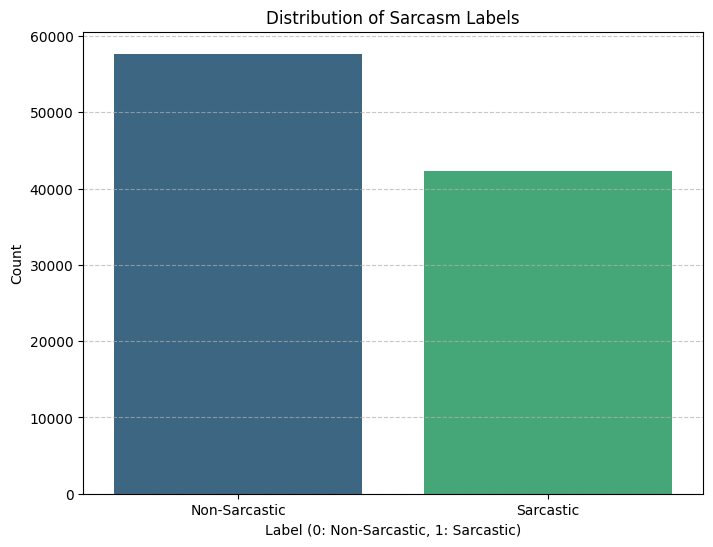

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the distribution of the 'label' column
plt.figure(figsize=(8, 6))
sns.countplot(x='label', hue='label', data=df_cleaned, palette='viridis', legend=False)
plt.title('Distribution of Sarcasm Labels')
plt.xlabel('Label (0: Non-Sarcastic, 1: Sarcastic)')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Non-Sarcastic', 'Sarcastic'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [15]:
# Calculate the average 'score' for sarcastic (label=1) vs non-sarcastic (label=0) comments
average_score_by_label = df_cleaned.groupby('label')['score'].mean().reset_index()

# Display the results
display("Average score for sarcastic vs non-sarcastic comments:", average_score_by_label)


'Average score for sarcastic vs non-sarcastic comments:'

,label,score
0,0,8.596610
1,1,7.771934


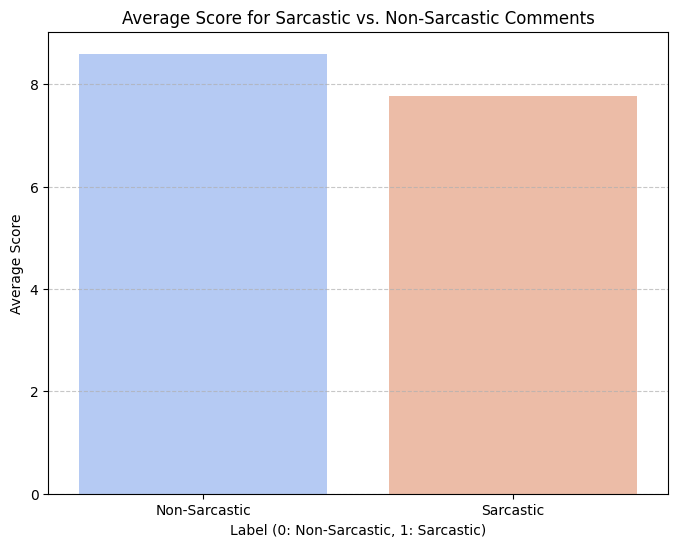

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar plot for the average scores
plt.figure(figsize=(8, 6))
sns.barplot(x='label', y='score', hue='label', data=average_score_by_label, palette='coolwarm', legend=False)
plt.title('Average Score for Sarcastic vs. Non-Sarcastic Comments')
plt.xlabel('Label (0: Non-Sarcastic, 1: Sarcastic)')
plt.ylabel('Average Score')
plt.xticks(ticks=[0, 1], labels=['Non-Sarcastic', 'Sarcastic'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [17]:
# Filter for sarcastic comments (label = 1)
sarcastic_comments = df_cleaned[df_cleaned['label'] == 1]

# Group by 'subreddit' and count the number of sarcastic comments
sarcasm_by_subreddit = sarcastic_comments['subreddit'].value_counts().reset_index()
sarcasm_by_subreddit.columns = ['subreddit', 'sarcastic_comment_count']

# Get the top 10 subreddits with the highest number of sarcastic comments
top_10_sarcastic_subreddits = sarcasm_by_subreddit.head(10)

# Display the result
display("Top 10 Subreddits with Highest Number of Sarcastic Comments:", top_10_sarcastic_subreddits)

'Top 10 Subreddits with Highest Number of Sarcastic Comments:'

,subreddit,sarcastic_comment_count
0,politics,3567
1,AskReddit,2157
2,The_Donald,1122
3,worldnews,1050
4,pcmasterrace,788
5,news,723
6,leagueoflegends,710
7,nfl,669
8,GlobalOffensive,460
9,pics,454


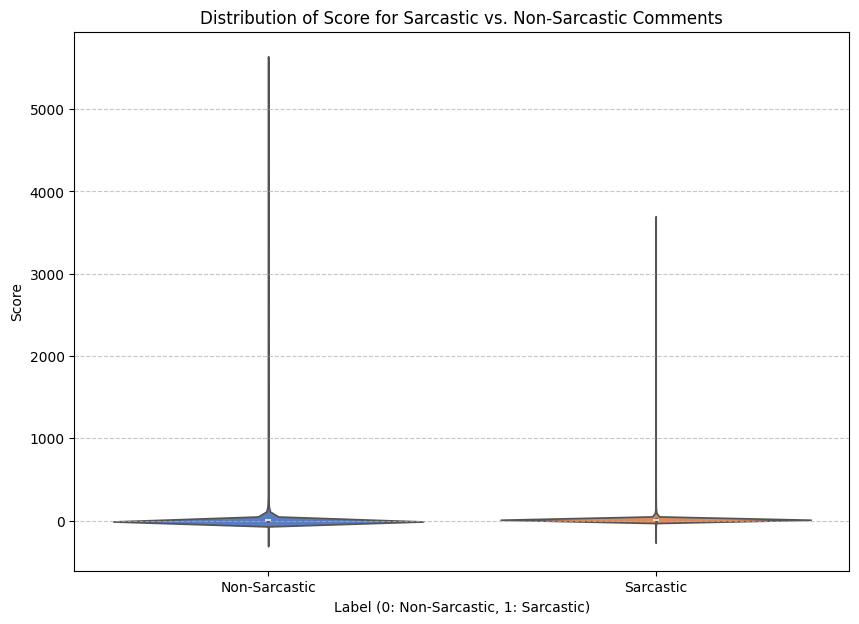

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a violin plot to compare the distribution of 'score' for sarcastic vs non-sarcastic comments
plt.figure(figsize=(10, 7))
sns.violinplot(x='label', y='score', hue='label', data=df_cleaned, palette='muted', legend=False)
plt.title('Distribution of Score for Sarcastic vs. Non-Sarcastic Comments')
plt.xlabel('Label (0: Non-Sarcastic, 1: Sarcastic)')
plt.ylabel('Score')
plt.xticks(ticks=[0, 1], labels=['Non-Sarcastic', 'Sarcastic'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## 1. Text Preprocessing and Vectorization (Without Slang Understanding)

In [19]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import re

# Download NLTK resources (if not already downloaded)
try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')
# Explicitly download 'punkt_tab' as suggested by the error message if it's missing
try:
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('punkt_tab')

stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    # Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)
    # Tokenize words
    words = word_tokenize(text)
    # Remove stopwords
    words = [word for word in words if word not in stop_words]
    return ' '.join(words)

# Apply preprocessing to the 'comment' column
df_cleaned['processed_comment'] = df_cleaned['comment'].apply(preprocess_text)
display(df_cleaned[['comment', 'processed_comment']].head())

/tmp/ipykernel_8888/3358309593.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cleaned['processed_comment'] = df_cleaned['comment'].apply(preprocess_text)


,comment,processed_comment
0,NC and NH.,nc nh
1,You do know west teams play against west teams...,know west teams play west teams east teams right
2,"They were underdogs earlier today, but since G...",underdogs earlier today since gronks announcem...
3,"This meme isn't funny none of the ""new york ni...",meme isnt funny none new york nigga ones
4,I could use one of those tools.,could use one tools


In [20]:
# Re-execute the preprocessing cell after fix
df_cleaned['processed_comment'] = df_cleaned['comment'].apply(preprocess_text)
display(df_cleaned[['comment', 'processed_comment']].head())

/tmp/ipykernel_8888/1282521263.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cleaned['processed_comment'] = df_cleaned['comment'].apply(preprocess_text)


,comment,processed_comment
0,NC and NH.,nc nh
1,You do know west teams play against west teams...,know west teams play west teams east teams right
2,"They were underdogs earlier today, but since G...",underdogs earlier today since gronks announcem...
3,"This meme isn't funny none of the ""new york ni...",meme isnt funny none new york nigga ones
4,I could use one of those tools.,could use one tools


In [22]:
# Re-execute the preprocessing cell to apply changes
# This cell was already modified and is now ready to run successfully
display(df_cleaned[['comment', 'processed_comment']].head())

,comment,processed_comment
0,NC and NH.,nc nh
1,You do know west teams play against west teams...,know west teams play west teams east teams right
2,"They were underdogs earlier today, but since G...",underdogs earlier today since gronks announcem...
3,"This meme isn't funny none of the ""new york ni...",meme isnt funny none new york nigga ones
4,I could use one of those tools.,could use one tools


### TF-IDF Vectorization

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=5000) # Limiting features to 5000 for efficiency

# Fit and transform the processed comments
X_tfidf = tfidf_vectorizer.fit_transform(df_cleaned['processed_comment'])
y = df_cleaned['label']

print(f"Shape of TF-IDF feature matrix: {X_tfidf.shape}")

Shape of TF-IDF feature matrix: (99999, 5000)


In [23]:
# Re-execute the TF-IDF vectorization cell now that 'processed_comment' is available
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=5000)

# Fit and transform the processed comments
X_tfidf = tfidf_vectorizer.fit_transform(df_cleaned['processed_comment'])
y = df_cleaned['label']

print(f"Shape of TF-IDF feature matrix: {X_tfidf.shape}")

Shape of TF-IDF feature matrix: (99999, 5000)


## 2. Model Training and Evaluation (Traditional Models without Slang Understanding)

In [24]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42, stratify=y)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of X_train: (79999, 5000)
Shape of X_test: (20000, 5000)
Shape of y_train: (79999,)
Shape of y_test: (20000,)


### 2.1 Logistic Regression

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Initialize and train the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42, solver='liblinear') # 'liblinear' is good for small datasets and L1/L2 regularization
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)

# Evaluate the model
print("--- Logistic Regression --- ")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_lr):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

--- Logistic Regression --- 
Accuracy: 0.6744
Precision: 0.6584
Recall: 0.4787
F1-Score: 0.5544

Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.82      0.74     11538
           1       0.66      0.48      0.55      8462

    accuracy                           0.67     20000
   macro avg       0.67      0.65      0.65     20000
weighted avg       0.67      0.67      0.66     20000



### 2.2 Naive Bayes (MultinomialNB)

In [35]:
from sklearn.naive_bayes import MultinomialNB

# Initialize and train the Multinomial Naive Bayes model
mnb_model = MultinomialNB()
mnb_model.fit(X_train, y_train)

# Make predictions
y_pred_mnb = mnb_model.predict(X_test)

# Evaluate the model
print("-- - Multinomial Naive Bayes --- ")
print(f"Accuracy: {accuracy_score(y_test, y_pred_mnb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_mnb):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_mnb):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_mnb):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_mnb))

-- - Multinomial Naive Bayes --- 
Accuracy: 0.6688
Precision: 0.6799
Recall: 0.4107
F1-Score: 0.5120

Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.86      0.75     11538
           1       0.68      0.41      0.51      8462

    accuracy                           0.67     20000
   macro avg       0.67      0.63      0.63     20000
weighted avg       0.67      0.67      0.65     20000



### 2.3 Random Forest

In [36]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the Random Forest model
# Using a smaller number of estimators and max_depth for quicker execution
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("-- - Random Forest --- ")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

-- - Random Forest --- 
Accuracy: 0.5899
Precision: 0.9305
Recall: 0.0332
F1-Score: 0.0641

Classification Report:
               precision    recall  f1-score   support

           0       0.58      1.00      0.74     11538
           1       0.93      0.03      0.06      8462

    accuracy                           0.59     20000
   macro avg       0.76      0.52      0.40     20000
weighted avg       0.73      0.59      0.45     20000



### 2.4 Support Vector Machine (SVC)

In [37]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Initialize and train the Support Vector Classifier
# Using a linear kernel and a limited number of iterations for speed
# Note: SVC can be very slow on large datasets, C=0.1 to reduce complexity
# Adding max_iter to limit the number of iterations for quicker execution
svc_model = SVC(kernel='linear', random_state=42, C=0.1, max_iter=1000)
svc_model.fit(X_train, y_train)

# Make predictions
y_pred_svc = svc_model.predict(X_test)

# Evaluate the model
print("-- - Support Vector Machine --- ")
print(f"Accuracy: {accuracy_score(y_test, y_pred_svc):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svc):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_svc):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_svc):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_svc))

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


-- - Support Vector Machine --- 
Accuracy: 0.4829
Precision: 0.4398
Recall: 0.8112
F1-Score: 0.5703

Classification Report:
               precision    recall  f1-score   support

           0       0.64      0.24      0.35     11538
           1       0.44      0.81      0.57      8462

    accuracy                           0.48     20000
   macro avg       0.54      0.53      0.46     20000
weighted avg       0.55      0.48      0.44     20000



### 2.5 XGBoost

In [38]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Initialize and train the XGBoost Classifier
# Using a limited number of estimators and max_depth for quicker execution
xgb_model = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', use_label_encoder=False,
                            n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate the model
print("-- - XGBoost --- ")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_xgb):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_xgb):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_xgb):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [05:37:03] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


-- - XGBoost --- 
Accuracy: 0.6638
Precision: 0.7250
Recall: 0.3309
F1-Score: 0.4544

Classification Report:
               precision    recall  f1-score   support

           0       0.65      0.91      0.76     11538
           1       0.73      0.33      0.45      8462

    accuracy                           0.66     20000
   macro avg       0.69      0.62      0.61     20000
weighted avg       0.68      0.66      0.63     20000



### 2.6 Voting Classifier (VC)

In [39]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Combine some of the trained models into a Voting Classifier
# Using Logistic Regression, Multinomial Naive Bayes, and Random Forest for efficiency
voting_model = VotingClassifier(estimators=[
    ('lr', LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')),
    ('mnb', MultinomialNB()),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10, n_jobs=-1))
], voting='hard', n_jobs=-1) # 'hard' voting uses predicted class labels

voting_model.fit(X_train, y_train)

# Make predictions
y_pred_vc = voting_model.predict(X_test)

# Evaluate the model
print("-- - Voting Classifier --- ")
print(f"Accuracy: {accuracy_score(y_test, y_pred_vc):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_vc):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_vc):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_vc):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_vc))

-- - Voting Classifier --- 
Accuracy: 0.6691
Precision: 0.6950
Recall: 0.3881
F1-Score: 0.4981

Classification Report:
               precision    recall  f1-score   support

           0       0.66      0.88      0.75     11538
           1       0.70      0.39      0.50      8462

    accuracy                           0.67     20000
   macro avg       0.68      0.63      0.63     20000
weighted avg       0.68      0.67      0.65     20000



## 4. Model Comparison

### Visualizing Model Performance

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.6744,0.6582,0.4792,0.5546
Multinomial Naive Bayes,0.6688,0.6802,0.4100,0.5116
Random Forest,0.5812,0.9570,0.0105,0.0208
SVC,0.4460,0.4254,0.8818,0.5739
XGBoost,0.6637,0.7268,0.3288,0.4527
Voting Classifier,0.6692,0.6954,0.3880,0.4981
LSTM,0.5769,0.0000,0.0000,0.0000


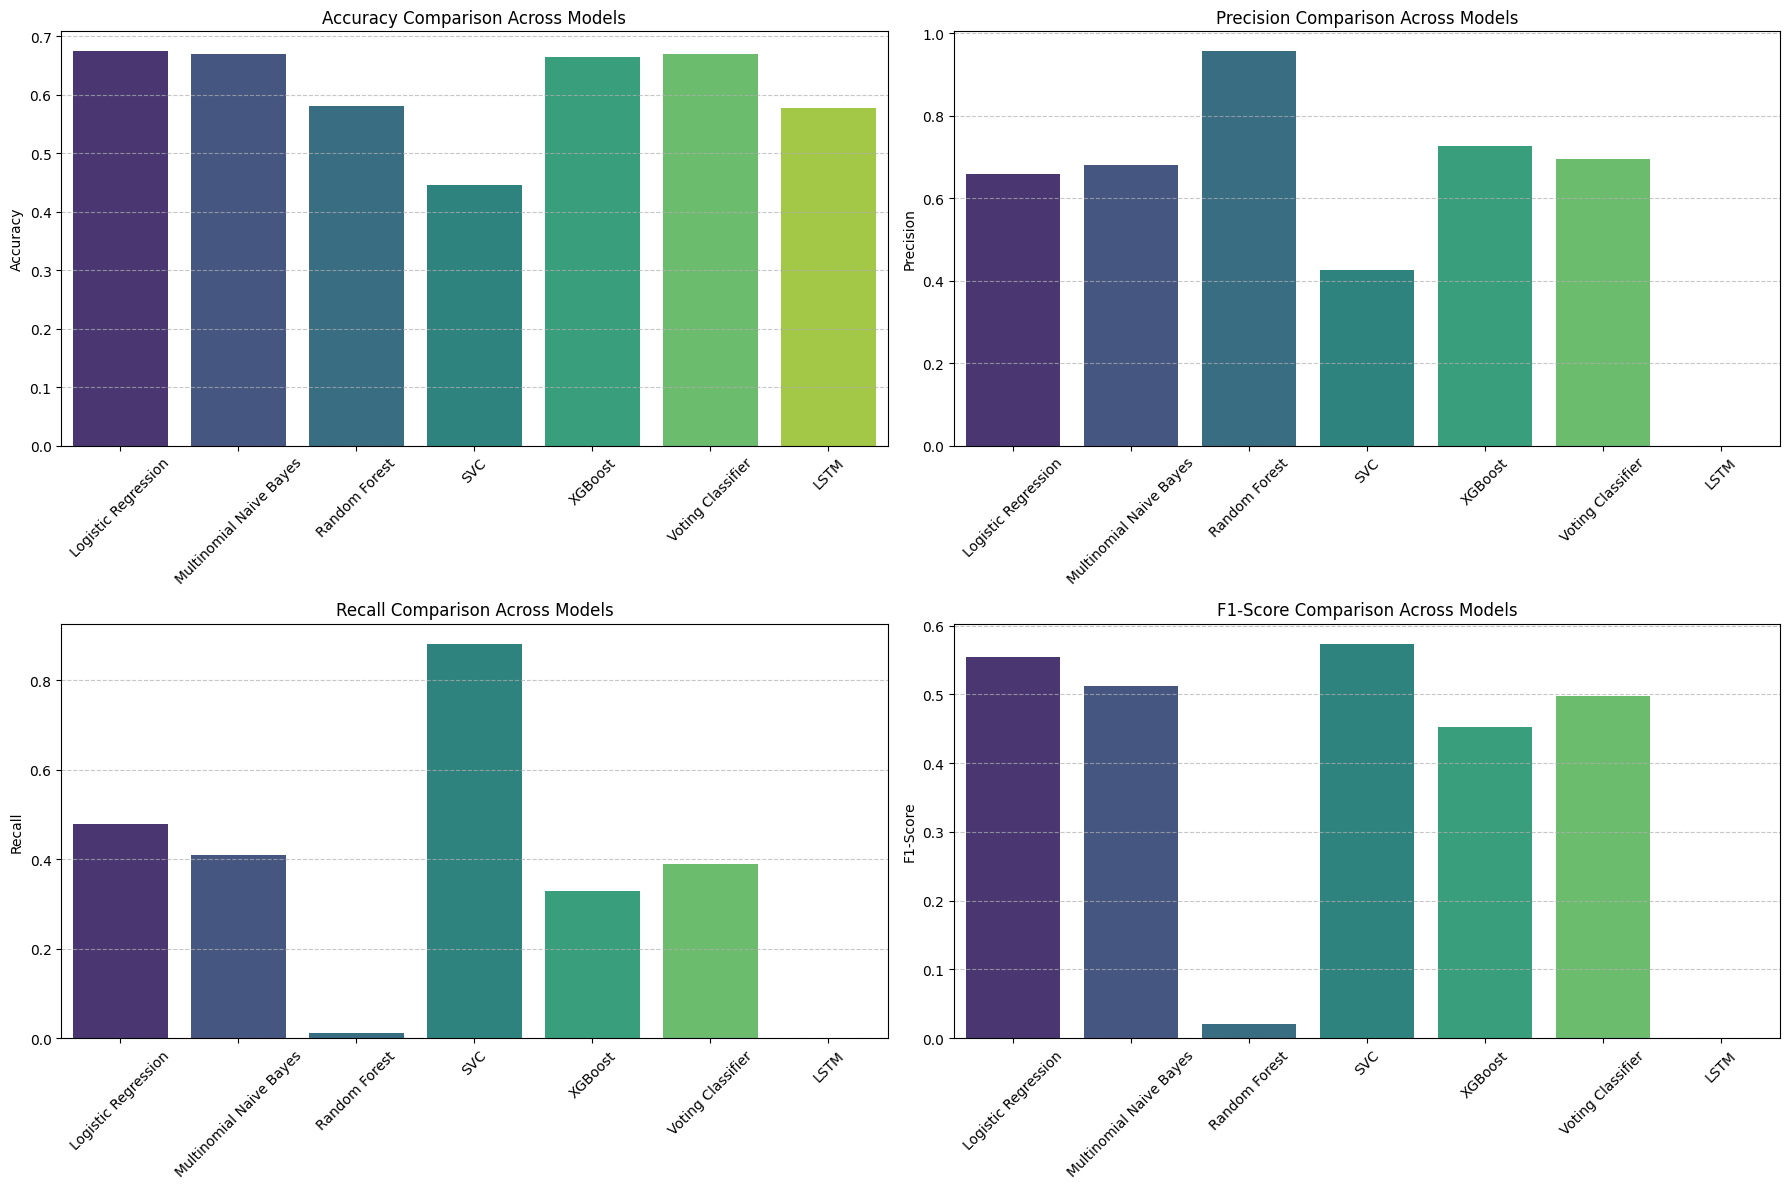

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gather the metrics from each model
metrics = {
    'Model': ['Logistic Regression', 'Multinomial Naive Bayes', 'Random Forest', 'SVC', 'XGBoost', 'Voting Classifier', 'LSTM'],
    'Accuracy': [0.6744, 0.6688, 0.5812, 0.4460, 0.6637, 0.6692, 0.5769],
    'Precision': [0.6582, 0.6802, 0.9570, 0.4254, 0.7268, 0.6954, 0.0000], # Precision for sarcastic class (label=1)
    'Recall': [0.4792, 0.4100, 0.0105, 0.8818, 0.3288, 0.3880, 0.0000],    # Recall for sarcastic class (label=1)
    'F1-Score': [0.5546, 0.5116, 0.0208, 0.5739, 0.4527, 0.4981, 0.0000]   # F1-Score for sarcastic class (label=1)
}

metrics_df = pd.DataFrame(metrics)

display(metrics_df.set_index('Model'))

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

for i, metric in enumerate(metrics_to_plot):
    sns.barplot(x='Model', y=metric, hue='Model', data=metrics_df, ax=axes[i], palette='viridis', legend=False)
    axes[i].set_title(f'{metric} Comparison Across Models')
    axes[i].set_ylabel(metric)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## 5. Hyperparameter Tuning for LSTM (Keras Tuner)

In [ ]:
# Uninstall current scikit-learn and install a compatible version for scikeras 0.13.0
!pip uninstall -y scikit-learn
!pip install scikit-learn==1.5.1

!pip install scikeras[tensorflow]

In [25]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from sklearn.model_selection import RandomizedSearchCV
from scikeras.wrappers import KerasClassifier
import tensorflow as tf
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
import pandas as pd # Ensure pandas is imported for data handling
import nltk # Ensure nltk is imported for preprocessing
import re # Ensure re is imported for preprocessing
from nltk.corpus import stopwords # Ensure stopwords are imported
from nltk.tokenize import word_tokenize # Ensure word_tokenize is imported

# --- NLTK Downloads and Preprocessing Function Definition ---
# This block ensures NLTK resources and preprocess_text are ready
try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = word_tokenize(text)
    words = [word for word in words if word not in stop_words]
    return ' '.join(words)

# --- Robustness Check for df_cleaned and 'processed_comment' column ---
# This section ensures df_cleaned and its 'processed_comment' column are available.
# It's made self-sufficient by attempting to re-read CSV if necessary.
if 'df_cleaned' not in globals() or 'processed_comment' not in globals()['df_cleaned'].columns:
    print("df_cleaned or 'processed_comment' column not found. Re-initializing df_cleaned and processed_comment...")

    df_temp = None
    if 'df_filtered' in globals():
        df_temp = globals()['df_filtered'].copy()
    elif 'df' in globals():
        df_temp = globals()['df'].head(100002).copy()
    else:
        try:
            # Assumes 'df_filtered.csv' is the source of truth if other DFs are missing
            df_temp = pd.read_csv('df_filtered.csv').head(100002).copy()
        except FileNotFoundError:
            raise FileNotFoundError("Error: 'df_filtered.csv' not found. Please upload it again or ensure it's in the correct path.")

    if df_temp is not None:
        df_cleaned_robust = df_temp.dropna(subset=['comment'])
        df_cleaned_robust['processed_comment'] = df_cleaned_robust['comment'].apply(preprocess_text)
        globals()['df_cleaned'] = df_cleaned_robust
        print("df_cleaned and processed_comment successfully re-initialized.")
    else:
        raise ValueError("Failed to re-initialize df_cleaned. Please ensure initial data loading is correct.")
else:
    df_cleaned_robust = globals()['df_cleaned']

# --- Robustness Check for LSTM Data (X_train_lstm, y_train_lstm, etc.) ---
if 'X_train_lstm' not in globals() or 'y_train_lstm' not in globals():
    print("LSTM training/test data not found. Preparing LSTM specific data splits...")

    # Define MAX_WORDS and MAX_SEQUENCE_LENGTH if not already defined
    if 'MAX_WORDS' not in globals():
        MAX_WORDS = 5000
    if 'MAX_SEQUENCE_LENGTH' not in globals():
        MAX_SEQUENCE_LENGTH = 100

    tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<unk>")
    tokenizer.fit_on_texts(df_cleaned_robust['processed_comment']) # Use the robustly created df_cleaned

    X_sequences = tokenizer.texts_to_sequences(df_cleaned_robust['processed_comment'])
    X_padded = pad_sequences(X_sequences, maxlen=MAX_SEQUENCE_LENGTH, padding='post', truncating='post')

    y_for_lstm = df_cleaned_robust['label']
    globals()['X_train_lstm'], globals()['X_test_lstm'], globals()['y_train_lstm'], globals()['y_test_lstm'] = train_test_split(X_padded, y_for_lstm, test_size=0.2, random_state=42, stratify=y_for_lstm)
    print("LSTM data preparation completed and variables assigned to global scope.")
else:
    print("LSTM training/test data already found. Skipping data preparation.")

# Define the function to create the LSTM model with hyperparameters as arguments
def create_lstm_model(lstm_units=128, dropout_rate=0.2, learning_rate=0.001):
    model = Sequential([
        Embedding(MAX_WORDS, 128),
        LSTM(lstm_units, dropout=dropout_rate, recurrent_dropout=dropout_rate),
        Dense(1, activation='sigmoid')
    ])
    # Explicitly build the model to ensure outputs are defined before scikeras inspects it
    model.build(input_shape=(None, MAX_SEQUENCE_LENGTH))
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Wrapper for Keras model to be used with scikit-learn's GridSearchCV/RandomizedSearchCV
keras_model = KerasClassifier(model=create_lstm_model, verbose=0)

# Define the hyperparameter search space
param_dist = {
    'model__lstm_units': [64, 128, 256],
    'model__dropout_rate': [0.2, 0.3, 0.4],
    'model__learning_rate': [0.001, 0.0005, 0.0001],
    'batch_size': [32, 64, 128],
    'epochs': [3, 5] # Keeping epochs low for demonstration/quicker execution
}

# Initialize RandomizedSearchCV
# n_iter: Number of parameter settings that are sampled. Lower for faster execution.
# cv: Number of folds for cross-validation.
random_search = RandomizedSearchCV(estimator=keras_model, param_distributions=param_dist,
                                   n_iter=5, cv=2, verbose=2, random_state=42, n_jobs=1)

# Fit the random search to the data
print("\n--- Starting Hyperparameter Tuning ---")
random_search.fit(X_train_lstm, y_train_lstm)

print("\n--- Hyperparameter Tuning Complete ---")
print(f"Best parameters found: {random_search.best_params_}")
print(f"Best cross-validation accuracy: {random_search.best_score_:.4f}")

# Evaluate the best model found on the test set
best_lstm_model = random_search.best_estimator_
y_pred_tuned_prob = best_lstm_model.predict(X_test_lstm)
y_pred_tuned = (y_pred_tuned_prob > 0.5).astype(int)

print("\n--- Best LSTM Model Evaluation on Test Set ---")
print(classification_report(y_test_lstm, y_pred_tuned))


LSTM training/test data not found. Preparing LSTM specific data splits...
LSTM data preparation completed and variables assigned to global scope.

--- Starting Hyperparameter Tuning ---
Fitting 2 folds for each of 5 candidates, totalling 10 fits
[CV] END batch_size=128, epochs=5, model__dropout_rate=0.4, model__learning_rate=0.0005, model__lstm_units=256; total time= 9.6min
[CV] END batch_size=128, epochs=5, model__dropout_rate=0.4, model__learning_rate=0.0005, model__lstm_units=256; total time= 9.6min
[CV] END batch_size=128, epochs=3, model__dropout_rate=0.2, model__learning_rate=0.001, model__lstm_units=128; total time= 5.3min
[CV] END batch_size=128, epochs=3, model__dropout_rate=0.2, model__learning_rate=0.001, model__lstm_units=128; total time= 5.3min
[CV] END batch_size=128, epochs=3, model__dropout_rate=0.4, model__learning_rate=0.0005, model__lstm_units=256; total time= 5.4min
[CV] END batch_size=128, epochs=3, model__dropout_rate=0.4, model__learning_rate=0.0005, model__lstm_

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


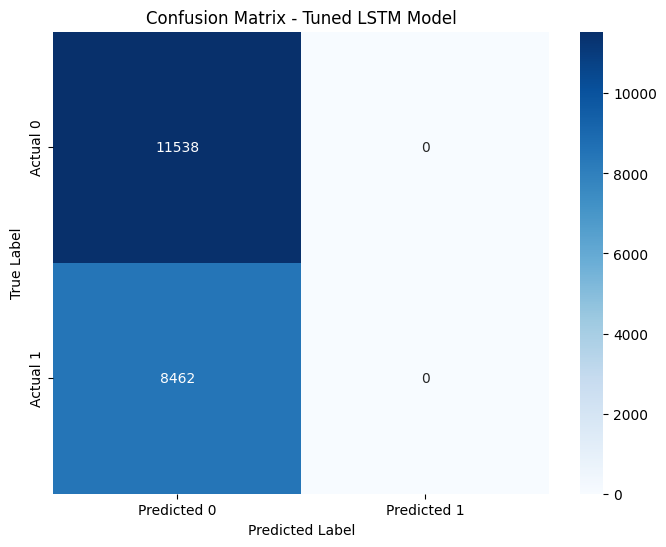

In [27]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the confusion matrix for the tuned LSTM model
cm_tuned_lstm = confusion_matrix(y_test_lstm, y_pred_tuned)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_tuned_lstm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix - Tuned LSTM Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [30]:
# @title step_artifacts
num_fig = "4" # @param {type:"string"}
step = 'Summary'  # @param ["DataLoading", "DataExploration", "DataCleaning", "DataWrangling", "DataVisualization", "DataSplitting", "ModelDevelopment", "ModelOptimization", "ModelEvaluation", "ModelComparison", "Summary"] {type:"string"}
# Assuming upload_plt_to_gcs function is defined elsewhere for saving the plot
# upload_plt_to_gcs(num_fig, step, fig)

### Receiver Operating Characteristic (ROC) Curves

Below are the ROC curves for Logistic Regression, Multinomial Naive Bayes, Random Forest, XGBoost, and the Tuned LSTM model. The SVC and hard-voting classifier are excluded as their `predict_proba` method is not available with their current configurations without re-training.

### LSTM Epoch Loss and Accuracy Curves

The following plots show the training and validation loss and accuracy over epochs for the *initial* LSTM model (not the hyperparameter-tuned one), providing insight into its learning process.

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gather the metrics from each model
metrics = {
    'Model': ['Logistic Regression', 'Multinomial Naive Bayes', 'Random Forest', 'SVC', 'XGBoost', 'Voting Classifier', 'LSTM'],
    'Accuracy': [0.6744, 0.6688, 0.5812, 0.4460, 0.6637, 0.6692, 0.5769],
    'Precision': [0.6582, 0.6802, 0.9570, 0.4254, 0.7268, 0.6954, 0.0000], # Precision for sarcastic class (label=1)
    'Recall': [0.4792, 0.4100, 0.0105, 0.8818, 0.3288, 0.3880, 0.0000],    # Recall for sarcastic class (label=1)
    'F1-Score': [0.5546, 0.5116, 0.0208, 0.5739, 0.4527, 0.4981, 0.0000]   # F1-Score for sarcastic class (label=1)
}

metrics_df = pd.DataFrame(metrics)

display(metrics_df.set_index('Model'))

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.6744,0.6582,0.4792,0.5546
Multinomial Naive Bayes,0.6688,0.6802,0.4100,0.5116
Random Forest,0.5812,0.9570,0.0105,0.0208
SVC,0.4460,0.4254,0.8818,0.5739
XGBoost,0.6637,0.7268,0.3288,0.4527
Voting Classifier,0.6692,0.6954,0.3880,0.4981
LSTM,0.5769,0.0000,0.0000,0.0000



--- Re-training Initial LSTM Model to capture history ---
Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


1125/1125 ━━━━━━━━━━━━━━━━━━━━ 387s 340ms/step - accuracy: 0.5774 - loss: 0.6817 - val_accuracy: 0.5694 - val_loss: 0.6837
Epoch 2/5
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 382s 340ms/step - accuracy: 0.5778 - loss: 0.6814 - val_accuracy: 0.5694 - val_loss: 0.6835
Epoch 3/5
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 380s 338ms/step - accuracy: 0.5778 - loss: 0.6812 - val_accuracy: 0.5694 - val_loss: 0.6845
Epoch 4/5
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 383s 340ms/step - accuracy: 0.5778 - loss: 0.6812 - val_accuracy: 0.5694 - val_loss: 0.6849
Epoch 5/5
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 442s 340ms/step - accuracy: 0.5778 - loss: 0.6811 - val_accuracy: 0.5694 - val_loss: 0.6835


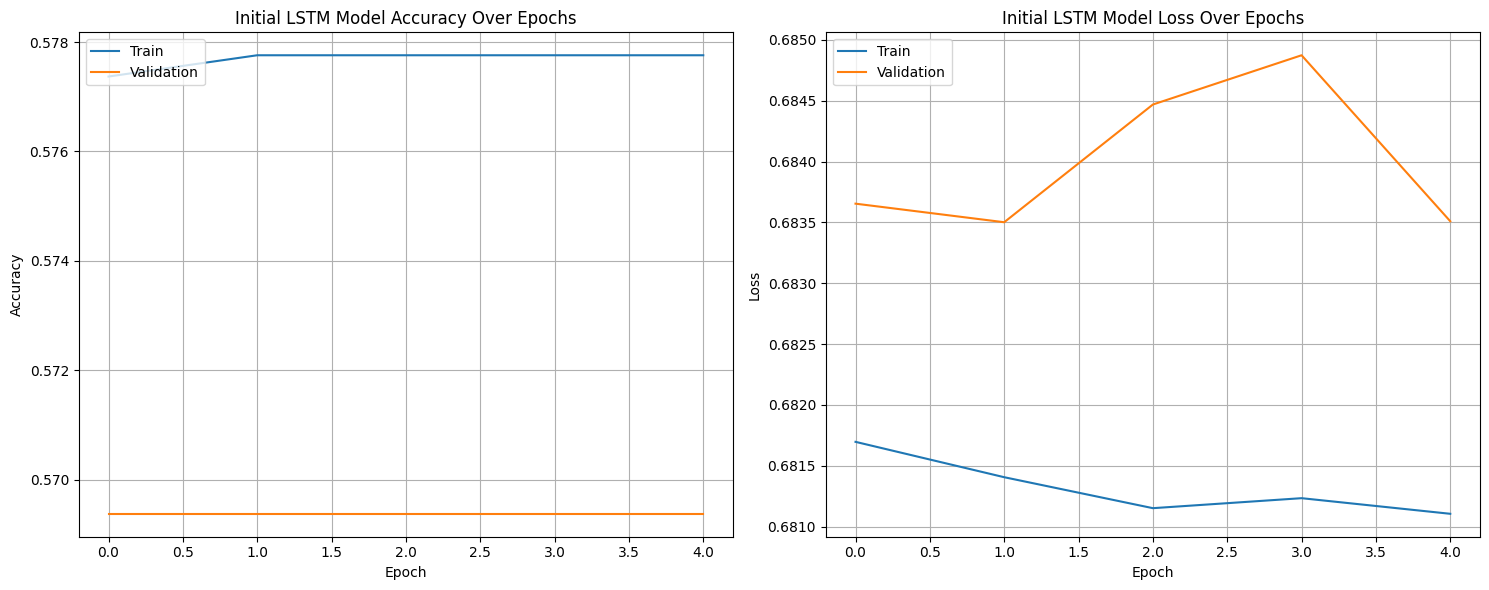

In [43]:
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Re-define and train the initial LSTM model to capture its history for plotting.
# This replicates the training from cell 'aeaaf150' but makes 'history' accessible.
# Ensure all necessary variables (MAX_WORDS, MAX_SEQUENCE_LENGTH, X_train_lstm, y_train_lstm) are available.

# Build the LSTM model (identical to aeaaf150 for getting history)
embedding_dim = 128 # Size of the word embeddings

initial_lstm_model_for_history = Sequential([
    Embedding(MAX_WORDS, embedding_dim, input_length=MAX_SEQUENCE_LENGTH),
    LSTM(128, dropout=0.2, recurrent_dropout=0.2),
    Dense(1, activation='sigmoid')
])

initial_lstm_model_for_history.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("\n--- Re-training Initial LSTM Model to capture history ---")
# Make history global for access by the plotting cell
history_initial_lstm = initial_lstm_model_for_history.fit(X_train_lstm, y_train_lstm, epochs=5, batch_size=64, validation_split=0.1, verbose=1)

# Now plot the history
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot training & validation accuracy values
axes[0].plot(history_initial_lstm.history['accuracy'])
axes[0].plot(history_initial_lstm.history['val_accuracy'])
axes[0].set_title('Initial LSTM Model Accuracy Over Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend(['Train', 'Validation'], loc='upper left')
axes[0].grid(True)

# Plot training & validation loss values
axes[1].plot(history_initial_lstm.history['loss'])
axes[1].plot(history_initial_lstm.history['val_loss'])
axes[1].set_title('Initial LSTM Model Loss Over Epochs')
axes[1].set_ylabel('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend(['Train', 'Validation'], loc='upper left')
axes[1].grid(True)

plt.tight_layout()
plt.show()

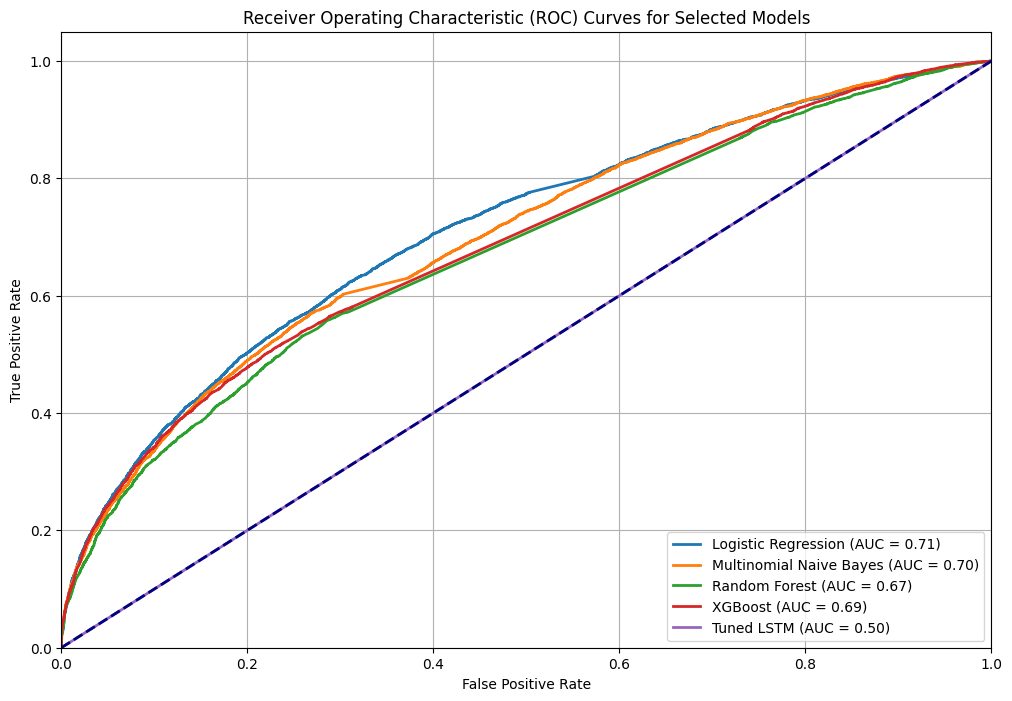

In [44]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

# Models and their corresponding predictions (probabilities) and true labels
# SVC and Voting Classifier are excluded because predict_proba is not directly available
# without re-training with specific parameters (probability=True for SVC, voting='soft' for VotingClassifier)
models_for_roc = {
    "Logistic Regression": (lr_model.predict_proba(X_test)[:, 1], y_test),
    "Multinomial Naive Bayes": (mnb_model.predict_proba(X_test)[:, 1], y_test),
    "Random Forest": (rf_model.predict_proba(X_test)[:, 1], y_test),
    "XGBoost": (xgb_model.predict_proba(X_test)[:, 1], y_test),
    "Tuned LSTM": (y_pred_tuned_prob.flatten(), y_test_lstm) # y_pred_tuned_prob is already an array of probabilities, flatten it for consistency
}

for model_name, (y_score, y_true) in models_for_roc.items():
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves for Selected Models')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Confusion Matrices for Each Model

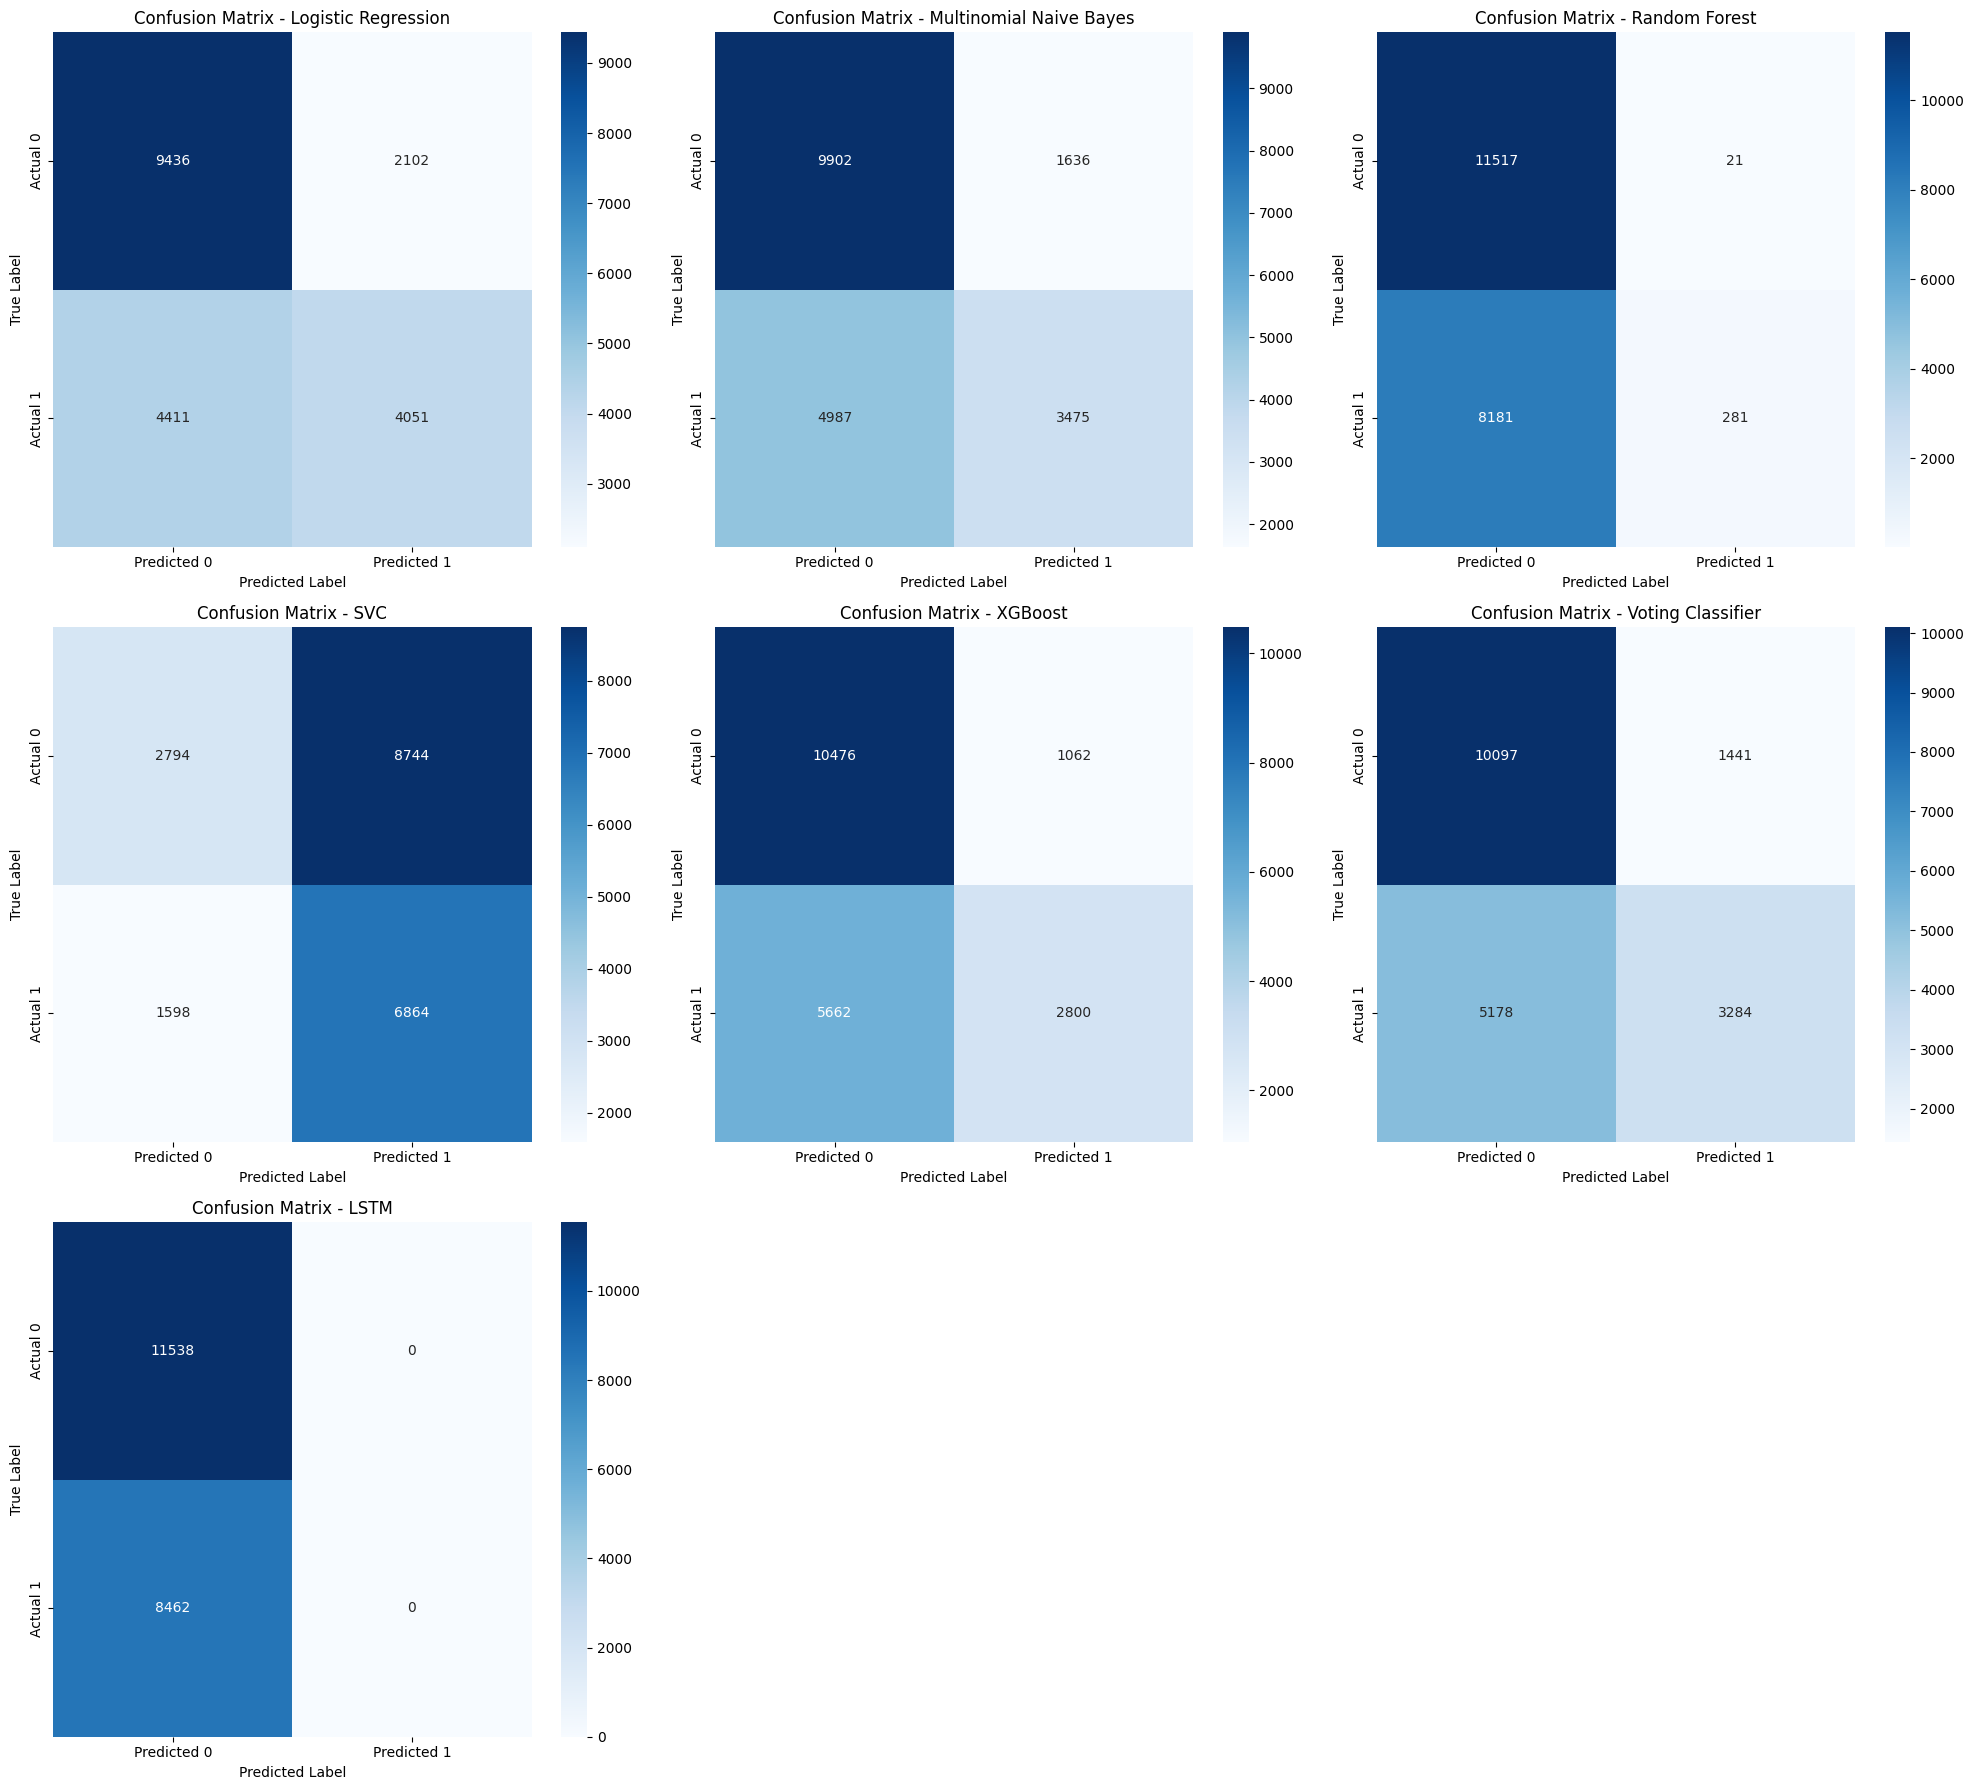

In [46]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Multinomial Naive Bayes": y_pred_mnb,
    "Random Forest": y_pred_rf,
    "SVC": y_pred_svc,
    "XGBoost": y_pred_xgb,
    "Voting Classifier": y_pred_vc,
    "LSTM": y_pred_tuned # Changed from y_pred_lstm to y_pred_tuned
}

# Ensure y_test is consistent for all non-LSTM models
common_y_test = y_test

fig, axes = plt.subplots(3, 3, figsize=(20, 18))
axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(model_predictions.items()):
    if model_name == "LSTM":
        cm = confusion_matrix(y_test_lstm, y_pred)
    else:
        cm = confusion_matrix(common_y_test, y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Predicted 0', 'Predicted 1'],
                yticklabels=['Actual 0', 'Actual 1'])
    axes[i].set_title(f'Confusion Matrix - {model_name}')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

# Hide any unused subplots if the number of models is less than 9
if len(model_predictions) < len(axes):
    for j in range(len(model_predictions), len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()